# Introduction to Neural Networks

## The multilayer perceptron (MLP)
<p align="center">
  <img src="../files/input_layer.gif" alt="An image entering the input layer of a neural network">
</p>

MLPs are the "hello world" of neural networks. An MLP is a type of artificial neural network that consists of multiple layers of interconnected **neurons**: an input layer, one or more **hidden layers**, and an output layer.

You can think of a **neuron** as a function. It takes input values and produces one output value called its **activation**. Inputs and activations are floating-point numbers (in the classic picture, between 0 and 1).

### 1. Input layer
The input layer receives the values from the data. It has one neuron for each input feature.

Imagine that we have images of handwritten digits from 0 to 9, each 28 × 28 pixels. Each pixel has a value between 0 and 1 representing its brightness. If we "flatten" the image into a 1-dimensional vector, we get a vector of length 784. This vector is the first layer of our network: each pixel is a neuron, and its brightness is that neuron's activation.

<p align="center">
  <img src="../files/pixels-as-input.png" alt="Pixels of a handwritten 7 flattened into input neurons">
</p>

An MLP is **fully connected**: each neuron in a layer is connected to every neuron in the previous layer.

### 2. Hidden layers
The hidden layers sit between the input layer and the output layer, and this is where the "magic" happens. Each hidden layer takes the activations of the previous layer and produces a new vector of activations. The number of hidden layers and the number of neurons in each are **hyperparameters**: choices we make and can tune to improve performance.

The activation of neuron $k$ in layer $l$ is computed from all activations in the previous layer $l-1$:

$$a_k^{(l)} = \sigma\left(\sum_{i=1}^{n} w_{k,i}\, a_i^{(l-1)} + b_k\right)$$

where:
- $a_i^{(l-1)}$ is the activation of neuron $i$ in the previous layer (which has $n$ neurons), and $a_k^{(l)}$ is the activation of neuron $k$ in layer $l$.
- $w_{k,i}$ is the **weight**: the strength of the connection between neuron $i$ and neuron $k$.
- $b_k$ is the **bias**: a constant added to the weighted sum. You can think of it as a threshold that controls how large the weighted sum $\sum_i w_{k,i}\, a_i^{(l-1)}$ must be before neuron $k$ becomes active.
- $\sigma$ is the **activation function**, a non-linear function applied to the result. It maps values that could range from $-\infty$ to $\infty$ into a limited range (classically 0 to 1). Common choices are sigmoid, hyperbolic tangent, ReLU, and Leaky ReLU (see below).

For a whole layer at once, this becomes a matrix equation:

$$\mathbf{a}^{(l)} = \sigma\left(W^{(l)}\, \mathbf{a}^{(l-1)} + \mathbf{b}^{(l)}\right)$$

- $\mathbf{a}^{(l)}$ is the vector of all activations in layer $l$.
- $W^{(l)}$ is the matrix of weights: rows are the neurons in layer $l$, columns are the neurons in layer $l-1$.
- $\mathbf{b}^{(l)}$ is the vector of biases, one per neuron in layer $l$.

Together, the weights and biases are the adjustable **parameters** of the network. Even a small fully connected network has many of them. For example, with 28 × 28 input images, two hidden layers of 5 neurons each, and an output layer of 10 neurons (one per digit 0 to 9):

| Connection | Weights | Biases |
|---|---|---|
| Input (784) → Hidden 1 (5) | 784 × 5 = 3,920 | 5 |
| Hidden 1 (5) → Hidden 2 (5) | 5 × 5 = 25 | 5 |
| Hidden 2 (5) → Output (10) | 5 × 10 = 50 | 10 |
| **Total** | **3,995** | **20** |

That is 4,015 adjustable parameters for a tiny network.

**Summary:** every neuron in layer $l$ is connected to every neuron in layer $l-1$. Each connection has its own weight, each neuron in layer $l$ has its own bias, and an activation function is applied to the result.

### 3. Output layer
The output layer produces the final values. For a classification problem it typically has one neuron per class, and its activations represent the "probability" that the input belongs to each class. It usually uses a different activation function than the hidden layers, the **softmax**:

$$\text{softmax}(x_i) = \frac{e^{x_i}}{\sum_{j=1}^{n} e^{x_j}}$$

which turns any set of numbers into positive values that sum to 1.

## Activation functions
Activation functions determine the output of a neuron given its weighted input. Popular choices:

| Name | Formula |
|---|---|
| Sigmoid | $S(x) = \dfrac{1}{1 + e^{-x}}$ |
| Hyperbolic tangent | $\tanh(x) = \dfrac{e^{x} - e^{-x}}{e^{x} + e^{-x}}$ |
| ReLU | $\max(0, x)$ |
| Leaky ReLU | $\max(0.01x,\ x)$ |

## Training neural networks
<p align="center">
  <img src="../files/mlp_training.gif" alt="Animation of an MLP being trained">
</p>

Training a neural network means adjusting its weights and biases using a dataset of input–output pairs. The goal is to minimize the error between the predicted and the actual outputs.

## Backpropagation
Backpropagation is the algorithm that tells us *how* to adjust each weight and bias to reduce the error. It uses the chain rule of calculus to compute the gradient of the error with respect to every parameter. Training repeats four steps:

### 1. Forward pass
The input data are passed through the network layer by layer. Each neuron computes a weighted sum of its inputs, applies its activation function, and passes the result to the next layer.

### 2. Loss calculation
A **loss function** measures the difference between the network's prediction and the true target, for example mean squared error for regression or cross-entropy for classification. This loss is the network's error.

### 3. Backward pass (backpropagation of errors)
- Backpropagation calculates how much each weight contributed to the error, by applying the **chain rule** to propagate the error backward through the network, from the output layer to the input layer.
- The result is the **gradient** of the loss with respect to each weight: how the loss would change if that weight changed a little.

<table>
  <tr>
    <td align="left" style="width: 50%;">
      <img src="../files/gradient_descent.gif" alt="Gradient descent on a loss surface">
    </td>
    <td align="right" style="width: 50%;">
      <img src="../files/propagate-backwards.png" alt="Errors propagating backwards through a network">
    </td>
  </tr>
</table>

[More details on backpropagation](http://neuralnetworksanddeeplearning.com/chap2.html)

### 4. Weight update
- The weights are moved a small step in the direction that reduces the loss (opposite to the gradient), using an **optimizer** such as stochastic gradient descent or **Adam**.
- Repeating this many times gradually improves the predictions.

### Key concepts
- **Chain rule:** lets backpropagation compute the gradients for all layers efficiently, starting from the output and working backward.
- **Gradient descent:** the update rule is $w \leftarrow w - \eta \, \dfrac{\partial L}{\partial w}$, where $\eta$ is the **learning rate** (step size) and $\dfrac{\partial L}{\partial w}$ is the gradient of the loss $L$ with respect to the weight $w$.
- **Epoch:** one full pass through the training data. Training runs for many epochs until the loss stops improving.

Variants of gradient descent differ in how much data they use for each update:
- **(Full-batch) gradient descent:** compute the gradient on the whole training set, then update.
- **Stochastic gradient descent (SGD):** update after every single randomly chosen example.
- **Mini-batch gradient descent:** update after each small batch of examples (e.g. 32). This is what is used in practice, including in the code below.

## Overfitting and underfitting
**Overfitting** occurs when a network learns the training data *too* well, including its noise, and does not generalize to new, unseen data. **Underfitting** occurs when the network fails to capture the underlying patterns, so it performs poorly on both training and test data.

To prevent **overfitting**:
- **More data or data augmentation:** artificially increase the variety of the training data (e.g. small rotations and shifts of images).
- **Regularization:** add a penalty to the loss that keeps the weights small and the model simple.
- **Dropout:** randomly switch off some neurons during training, so the network cannot rely on any single one.
- **Early stopping:** stop training when the validation loss starts to increase.

To prevent **underfitting**:
- Increase the capacity of the network (more hidden layers or more neurons per layer).
- Train for longer, or adjust the learning rate.

# Hands-on: Teaching a Computer to Read Handwritten Digits

In this lab we train a small neural network to recognize handwritten digits (0 to 9) from the **MNIST** dataset. We go step by step: look at the data, prepare it, build the model, watch one learning step up close, then train and check the results.

| Step | What happens |
|---|---|
| 1. Setup | load libraries and choose the experiment settings |
| 2. Data | see what an image looks like to a computer |
| 3. Preparation | normalize, augment, and batch the images |
| 4. Model | build an MLP: 784 → 128 → 64 → 10 |
| 5. One learning step | loss, gradients, and one weight update, up close |
| 6. Training | repeat for many epochs, tracking train and test accuracy |
| 7. Results | learning curves, example predictions, confusion matrix |
| 8. Experiments | change the settings and see what happens |

## Step 1: Setup
The settings below control the experiment. Later you can change them and rerun the notebook to see what happens.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)  # makes results repeatable, so everyone gets similar numbers

# Experiment settings: change these and rerun
USE_AUGMENTATION = True   # add random rotations/shifts to training images?
SUBSET_SIZE = 1000        # how many training images to use (full dataset has 60,000)
BATCH_SIZE = 32           # how many images the model sees before each update
NUM_EPOCHS = 50           # how many passes over the training data
LEARNING_RATE = 0.001     # how big each update step is

## Step 2: What does an image look like to a computer?

To us, an image is a picture. To a computer, it is a grid of numbers. Each MNIST image
is 28 x 28 pixels, and each pixel is a number from 0 (black) to 255 (white).

100%|██████████| 9.91M/9.91M [00:00<00:00, 10.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 372kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.91MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 4.70MB/s]


Image size: (28, 28)   Pixel values range from 0 to 255
Number of training images: 60,000


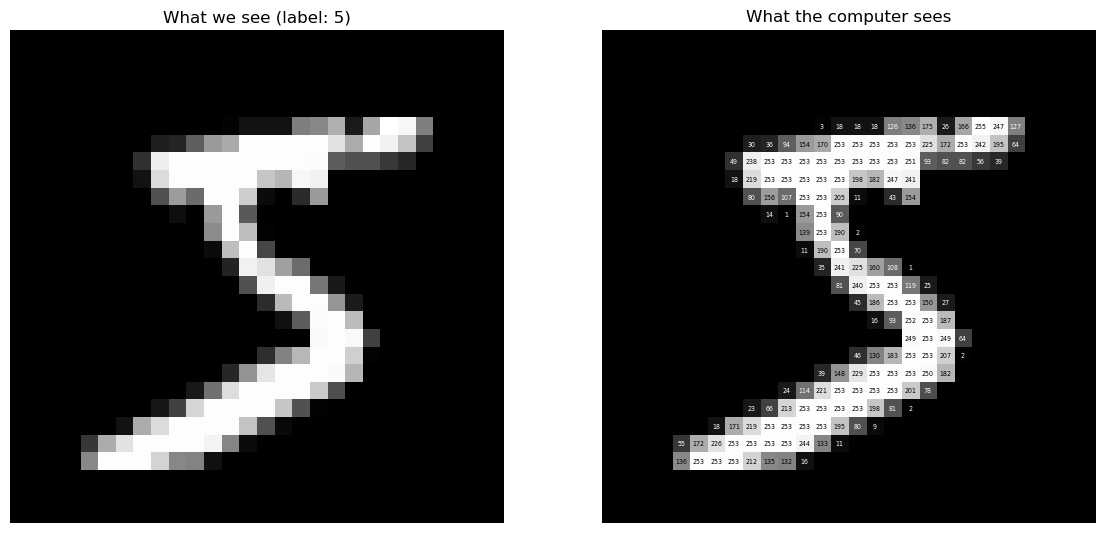

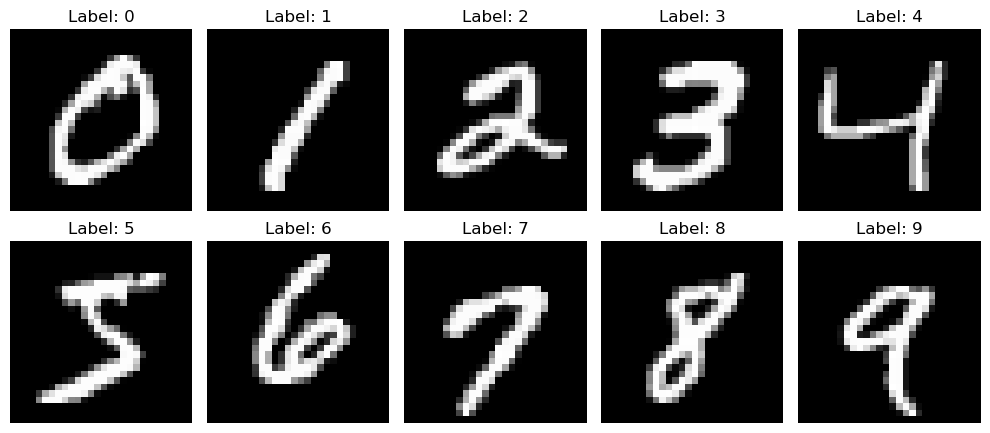

In [2]:
raw_train = datasets.MNIST(root='./data', train=True, download=True)  # no transforms: raw images
image, label = raw_train[0]
pixels = np.array(image)
print(f"Image size: {pixels.shape}   Pixel values range from {pixels.min()} to {pixels.max()}")
print(f"Number of training images: {len(raw_train):,}")

# The same image shown as a picture and as numbers
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(pixels, cmap='gray')
axes[0].set_title(f'What we see (label: {label})')
axes[1].imshow(pixels, cmap='gray')
for i in range(28):
    for j in range(28):
        if pixels[i, j] > 0:
            color = 'black' if pixels[i, j] > 128 else 'white'
            axes[1].text(j, i, pixels[i, j], ha='center', va='center', fontsize=4.5, color=color)
axes[1].set_title('What the computer sees')
for ax in axes:
    ax.axis('off')
plt.show()

# One example of each digit
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for digit, ax in enumerate(axes.flat):
    idx = (raw_train.targets == digit).nonzero()[0].item()
    ax.imshow(raw_train[idx][0], cmap='gray')
    ax.set_title(f'Label: {digit}')
    ax.axis('off')
plt.tight_layout()
plt.show()

## Step 3: Preparing the data

**Preprocessing.** Neural networks learn best when input numbers are small and centered
around zero. `ToTensor` scales pixels from 0..255 to 0..1, and `Normalize` shifts them
to -1..1.

**Augmentation.** With only 1,000 training images, the model can simply memorize them.
Augmentation creates slightly different versions of each image (rotated a little,
shifted a little) every time the model sees it, so it has to learn what a "7" looks
like in general. We only augment training images. Test images stay untouched, because
we want to measure performance on real, unmodified digits.

**Batches.** The model does not look at images one at a time. A `DataLoader` groups
them into batches of 32 and shuffles them each epoch.

Original pixels:  0 to 255
After ToTensor:   0.0 to 1.0
After Normalize:  -1.0 to 1.0
Tensor shape:     (1, 28, 28)  (channels, height, width)


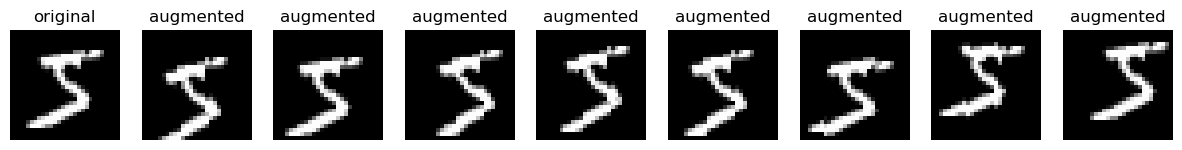

One batch of images: (32, 1, 28, 28)  (batch, channels, height, width)
One batch of labels: (32,)  first ten: [2, 9, 1, 2, 5, 2, 4, 2, 5, 6]


In [3]:
normalize = transforms.Compose([
    transforms.ToTensor(),                 # 0..255  ->  0..1
    transforms.Normalize((0.5,), (0.5,)),  # 0..1    -> -1..1
])
augment = transforms.Compose([
    transforms.RandomRotation(10),                     # rotate up to 10 degrees
    transforms.RandomAffine(0, translate=(0.1, 0.1)),  # shift up to 10% in each direction
])

# Preprocessing, step by step
as_tensor = transforms.ToTensor()(image)
normalized = normalize(image)
print(f"Original pixels:  {pixels.min()} to {pixels.max()}")
print(f"After ToTensor:   {as_tensor.min():.1f} to {as_tensor.max():.1f}")
print(f"After Normalize:  {normalized.min():.1f} to {normalized.max():.1f}")
print(f"Tensor shape:     {tuple(normalized.shape)}  (channels, height, width)")

# Augmentation: the same image, 8 random versions
fig, axes = plt.subplots(1, 9, figsize=(15, 2))
axes[0].imshow(image, cmap='gray')
axes[0].set_title('original')
for ax in axes[1:]:
    ax.imshow(augment(image), cmap='gray')
    ax.set_title('augmented')
for ax in axes:
    ax.axis('off')
plt.show()

# Build the datasets and loaders
def make_train_loader(use_augmentation):
    train_transform = transforms.Compose([augment, normalize]) if use_augmentation else normalize
    train_set = datasets.MNIST(root='./data', train=True, download=True, transform=train_transform)
    train_subset = Subset(train_set, range(SUBSET_SIZE))  # first SUBSET_SIZE images only
    return DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True)

train_loader = make_train_loader(USE_AUGMENTATION)
mnist_test = datasets.MNIST(root='./data', train=False, download=True, transform=normalize)
test_loader = DataLoader(mnist_test, batch_size=1000, shuffle=False)  # bigger batches just to evaluate faster

images, labels = next(iter(train_loader))
print(f"One batch of images: {tuple(images.shape)}  (batch, channels, height, width)")
print(f"One batch of labels: {tuple(labels.shape)}  first ten: {labels[:10].tolist()}")

## Step 4: Building the model

Our model is a **multilayer perceptron (MLP)**: a stack of fully connected layers.

```
 image 28x28  ->  flatten  ->  784  ->  128  ->  64  ->  10 scores
                                    ReLU     ReLU     (one per digit)
```

* **Flatten** unrolls the 28 x 28 grid into a single row of 784 numbers.
* Each **Linear** layer multiplies its inputs by learned weights and adds a bias.
* **ReLU** keeps positive numbers and sets negatives to zero. Without it, stacking
  layers would be no more powerful than a single layer.
* The output is 10 raw scores (called *logits*). The highest score is the model's guess.

In [4]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, 128)  # input -> hidden
        self.fc2 = nn.Linear(128, 64)       # hidden -> hidden
        self.fc3 = nn.Linear(64, 10)        # hidden -> output (one score per digit)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        return self.fc3(x)  # raw scores (logits); the loss function handles the rest

model = MLP()
print(model)

# How many numbers does the model learn?
print(f"\n{'layer':<12}{'shape':<14}{'parameters':>10}")
total = 0
for name, p in model.named_parameters():
    print(f"{name:<12}{str(list(p.shape)):<14}{p.numel():>10,}")
    total += p.numel()
print(f"Total learnable parameters: {total:,}")

# Follow one image through the network
x = images[:1]
print(f"\ninput        {tuple(x.shape)}")
x = model.flatten(x);          print(f"flatten      {tuple(x.shape)}")
x = model.relu(model.fc1(x));  print(f"fc1 + ReLU   {tuple(x.shape)}")
x = model.relu(model.fc2(x));  print(f"fc2 + ReLU   {tuple(x.shape)}")
x = model.fc3(x);              print(f"fc3          {tuple(x.shape)}  <- 10 scores")

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
  (relu): ReLU()
)

layer       shape         parameters
fc1.weight  [128, 784]       100,352
fc1.bias    [128]                128
fc2.weight  [64, 128]          8,192
fc2.bias    [64]                  64
fc3.weight  [10, 64]             640
fc3.bias    [10]                  10
Total learnable parameters: 109,386

input        (1, 1, 28, 28)
flatten      (1, 784)
fc1 + ReLU   (1, 128)
fc2 + ReLU   (1, 64)
fc3          (1, 10)  <- 10 scores


## Step 5: How the model learns, one step at a time

* The **loss function** (cross entropy) measures how wrong the predictions are.
  Lower is better.
* The **optimizer** (Adam) adjusts the weights to reduce the loss.

Before training, the model is just guessing. With 10 digits, a random guess is right
about 10% of the time, and the loss is about ln(10) = 2.30.

Every training step follows the same five moves:
1. clear old gradients
2. **forward pass**: make predictions
3. compute the loss
4. **backward pass**: work out how each weight affected the loss
5. update the weights a little

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Before training
with torch.no_grad():
    outputs = model(images)
    loss_before = criterion(outputs, labels).item()
    probs = torch.softmax(outputs[0], dim=0)  # softmax turns scores into probabilities
print(f"Untrained loss: {loss_before:.3f}  (random guessing gives about {np.log(10):.3f})")
print(f"Probabilities for the first image (true label {labels[0].item()}):")
print("  " + "  ".join(f"{d}:{p:.2f}" for d, p in enumerate(probs)))

# One training step, written out
model.train()
optimizer.zero_grad()              # 1. clear old gradients
outputs = model(images)            # 2. forward pass
loss = criterion(outputs, labels)  # 3. how wrong are we?
loss.backward()                    # 4. backward pass: compute gradients
optimizer.step()                   # 5. nudge the weights

with torch.no_grad():
    loss_after = criterion(model(images), labels).item()
print(f"\nLoss on this batch before the step: {loss_before:.3f}")
print(f"Loss on this batch after one step:  {loss_after:.3f}")
# Training is just this step repeated thousands of times.

Untrained loss: 2.384  (random guessing gives about 2.303)
Probabilities for the first image (true label 2):
  0:0.12  1:0.12  2:0.08  3:0.10  4:0.08  5:0.08  6:0.12  7:0.10  8:0.10  9:0.10

Loss on this batch before the step: 2.384
Loss on this batch after one step:  2.254


## Step 6: Training

Now we repeat that step over every batch (one **epoch**), and do this for many epochs.
After each epoch we also check the model on the **test set**: 10,000 images it never
trains on. This tells us whether it has really learned digits or just memorized
the training images.

We track four numbers per epoch: loss and accuracy on training data, and loss and
accuracy on test data.

In [6]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()  # training mode
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100 * correct / total


def evaluate(model, loader, criterion):
    model.eval()  # evaluation mode
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():  # no learning here, so no gradients needed
        for images, labels in loader:
            outputs = model(images)
            total_loss += criterion(outputs, labels).item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, 100 * correct / total


def train_model(train_loader, num_epochs=NUM_EPOCHS, lr=LEARNING_RATE):
    torch.manual_seed(42)
    model = MLP()  # start from a fresh, untrained model
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}

    for epoch in range(num_epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        test_loss, test_acc = evaluate(model, test_loader, criterion)
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)
        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1:3d} | train loss {train_loss:.3f}, acc {train_acc:5.1f}% "
                  f"| test loss {test_loss:.3f}, acc {test_acc:5.1f}%")
    return model, history


model, history = train_model(train_loader)

Epoch  10 | train loss 1.081, acc  64.4% | test loss 0.722, acc  78.6%
Epoch  20 | train loss 0.771, acc  75.8% | test loss 0.511, acc  84.6%
Epoch  30 | train loss 0.614, acc  79.9% | test loss 0.494, acc  84.1%
Epoch  40 | train loss 0.451, acc  85.7% | test loss 0.379, acc  88.5%
Epoch  50 | train loss 0.422, acc  86.8% | test loss 0.324, acc  90.2%


## Step 7: Results

**Learning curves.** If training accuracy keeps climbing while test accuracy stalls
(or test loss starts rising), the model is **overfitting**: memorizing the training
images instead of learning general patterns.

**Predictions.** Green titles are correct, red are wrong. The percentage is how
confident the model is.

**Confusion matrix.** Each row is the true digit, each column is the model's guess.
The diagonal counts correct answers; everything off the diagonal is a mistake.
Which digits get confused with each other most often? Does that make sense?

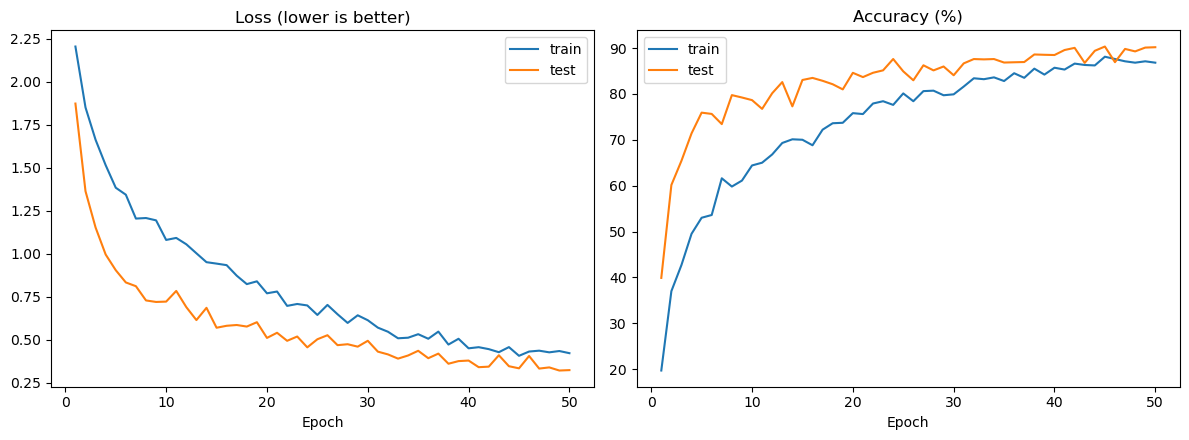

Final test accuracy: 90.2%


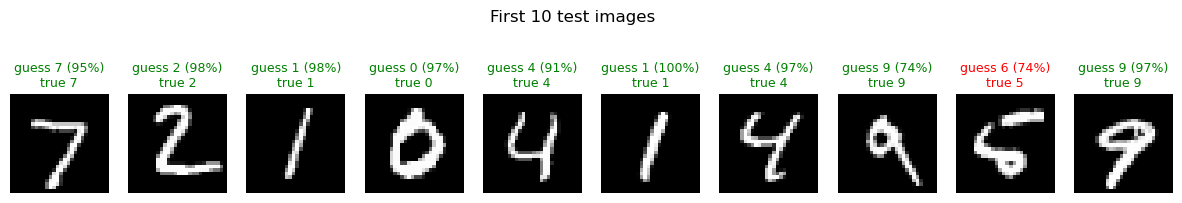

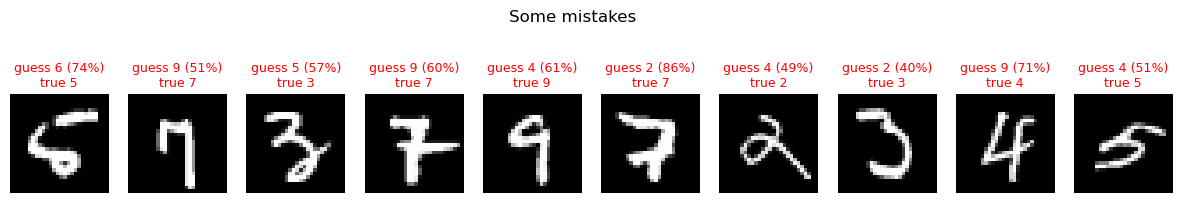

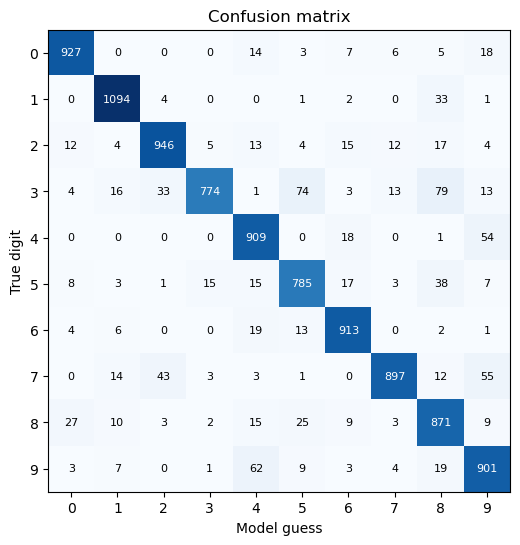

In [7]:
# Learning curves
epochs = range(1, len(history['train_loss']) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(epochs, history['train_loss'], label='train')
ax1.plot(epochs, history['test_loss'], label='test')
ax1.set_title('Loss (lower is better)')
ax1.set_xlabel('Epoch')
ax1.legend()
ax2.plot(epochs, history['train_acc'], label='train')
ax2.plot(epochs, history['test_acc'], label='test')
ax2.set_title('Accuracy (%)')
ax2.set_xlabel('Epoch')
ax2.legend()
plt.tight_layout()
plt.show()

# Predictions on the whole test set
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        all_preds.append(model(images).argmax(dim=1))
        all_labels.append(labels)
all_preds, all_labels = torch.cat(all_preds), torch.cat(all_labels)
print(f"Final test accuracy: {100 * (all_preds == all_labels).float().mean():.1f}%")

def show_predictions(indices, title):
    fig, axes = plt.subplots(1, len(indices), figsize=(15, 2.3))
    for ax, idx in zip(axes, indices):
        img, true = mnist_test[int(idx)]
        with torch.no_grad():
            probs = torch.softmax(model(img.unsqueeze(0)), dim=1)[0]
        pred = probs.argmax().item()
        ax.imshow(img.squeeze(), cmap='gray')
        ax.set_title(f'guess {pred} ({probs[pred]:.0%})\ntrue {true}',
                     color='green' if pred == true else 'red', fontsize=9)
        ax.axis('off')
    fig.suptitle(title, y=1.08)
    plt.show()

show_predictions(range(10), 'First 10 test images')
wrong = (all_preds != all_labels).nonzero().squeeze(1)
show_predictions(wrong[:10], 'Some mistakes')

# Confusion matrix
cm = torch.bincount(all_labels * 10 + all_preds, minlength=100).reshape(10, 10)
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm, cmap='Blues')
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j].item(), ha='center', va='center', fontsize=8,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xlabel('Model guess')
ax.set_ylabel('True digit')
ax.set_title('Confusion matrix')
plt.show()

## Step 8: Experiments to try

1. **Does augmentation help?** The code below trains twice, with and without
   augmentation, and plots both. Which one overfits more? Which ends with higher
   test accuracy?
2. **More data.** Change `SUBSET_SIZE` in Step 1 to 5000 or 10000 and rerun.
   How much does test accuracy improve? Is the overfitting gap smaller?
3. **Learning rate.** Try `LEARNING_RATE = 0.1` and `0.00001`. What goes wrong in
   each case?
4. **A different activation.** In Step 4, replace `nn.ReLU()` with `nn.PReLU()`, a
   version of ReLU that lets a small, learned amount of negative values through.
   Does it change anything?
5. **A bigger or smaller model.** Change 128 and 64 in Step 4. How does the number
   of parameters change? How does accuracy change?

Epoch  10 | train loss 1.081, acc  64.4% | test loss 0.722, acc  78.6%
Epoch  20 | train loss 0.771, acc  75.8% | test loss 0.511, acc  84.6%
Epoch  30 | train loss 0.614, acc  79.9% | test loss 0.494, acc  84.1%
Epoch  40 | train loss 0.451, acc  85.7% | test loss 0.379, acc  88.5%
Epoch  50 | train loss 0.422, acc  86.8% | test loss 0.324, acc  90.2%
Epoch  10 | train loss 0.276, acc  92.3% | test loss 0.521, acc  83.6%
Epoch  20 | train loss 0.124, acc  96.3% | test loss 0.575, acc  84.3%
Epoch  30 | train loss 0.030, acc  99.8% | test loss 0.594, acc  85.6%
Epoch  40 | train loss 0.013, acc 100.0% | test loss 0.634, acc  86.1%
Epoch  50 | train loss 0.005, acc 100.0% | test loss 0.688, acc  86.1%


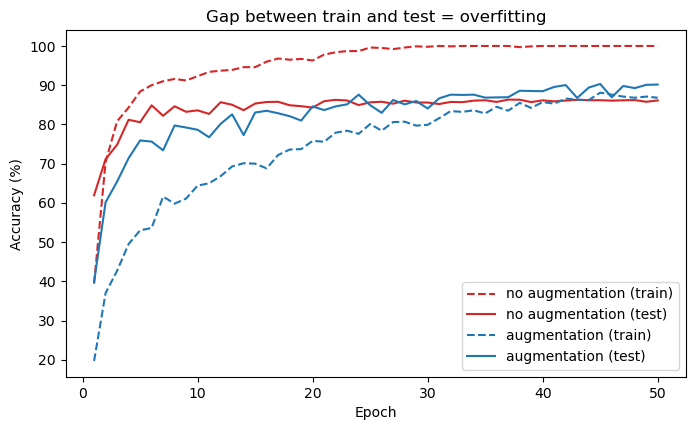

In [8]:
# Experiment 1: augmentation on vs off (takes a few minutes)
_, hist_aug = train_model(make_train_loader(True))
_, hist_plain = train_model(make_train_loader(False))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(epochs, hist_plain['train_acc'], '--', color='tab:red', label='no augmentation (train)')
ax.plot(epochs, hist_plain['test_acc'], color='tab:red', label='no augmentation (test)')
ax.plot(epochs, hist_aug['train_acc'], '--', color='tab:blue', label='augmentation (train)')
ax.plot(epochs, hist_aug['test_acc'], color='tab:blue', label='augmentation (test)')
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy (%)')
ax.set_title('Gap between train and test = overfitting')
ax.legend()
plt.show()